<a href="https://colab.research.google.com/github/jmarquez90/clip-siglip-memetic-analysis/blob/master/hateful-memes-clip-siglip.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Comparing CLIP and SigLIP for hateful-meme classification

This notebook evaluates whether frozen vision-language representations can identify hateful memes when paired with a simple, auditable linear classifier. It compares **CLIP** and **SigLIP** under the same train/development/test protocol and includes three ablations:

- image embeddings only;
- text embeddings only; and
- concatenated image + text embeddings.

The ablations matter because the Hateful Memes task is deliberately multimodal: a convincing model should gain signal from combining the image and overlaid text, not merely exploit one modality.

#### Methodology
We train embeddings for the dataset with CLIP and SigLIP but actual predictions are conducted by LPE (Linear Probe Evaluation). LPE allows us to use embeddings as attributes in what is otherwise a traditional linear model - in our case we use a logistic regression.

> **Content warning:** the source dataset contains hateful and discriminatory material. Example rendering is disabled by default. The dataset is not redistributed by this repository.


## 1. Environment and data layout

The reference environment uses Python 3.10+ and the versions in `requirements.txt`. The first code cell is a self-contained Colab bootstrap: in Colab it preserves the runtime's compiled scientific stack and installs only the model-specific dependencies; in a local checkout it uses `requirements.txt`. It also mounts Google Drive when available. A GPU is recommended for embedding extraction; the linear probes run on CPU.

Download the Hateful Memes dataset from its authorized source and arrange it as follows:

```text
<HATEFUL_MEMES_DATA_ROOT>/
└── hateful-memes/
    ├── train.jsonl
    ├── dev_seen.jsonl
    ├── test_seen.jsonl
    └── img/
        └── ...
```

Set `HATEFUL_MEMES_DATA_ROOT` to either the extracted `hateful-memes` directory or its parent. In Colab, the placeholder below points to a user-owned Drive folder without exposing a private URL or folder hierarchy.


In [20]:
# Colab/local bootstrap: safe to run before importing third-party packages.
import importlib.util
import os
import subprocess
import sys
from pathlib import Path

LOCAL_PACKAGES = [
    "joblib==1.5.2",
    "kagglehub==1.0.2",
    "matplotlib==3.10.7",
    "numpy==2.2.6",
    "pandas==2.3.3",
    "Pillow==11.3.0",
    "scikit-learn==1.7.2",
    "seaborn==0.13.2",
    "sentencepiece==0.2.2",
    "tqdm==4.67.1",
    "transformers==4.57.6",
]

COLAB_MODEL_PACKAGES = [
    "kagglehub==1.0.2",
    "sentencepiece==0.2.2",
    "transformers==4.57.6",
]
COLAB_RUNTIME_PACKAGES = {
    "joblib": "joblib",
    "matplotlib": "matplotlib",
    "numpy": "numpy",
    "pandas": "pandas",
    "PIL": "Pillow",
    "sklearn": "scikit-learn",
    "seaborn": "seaborn",
    "torch": "torch",
    "tqdm": "tqdm",
}
IN_COLAB_BOOTSTRAP = importlib.util.find_spec("google.colab") is not None

skip_install = os.environ.get("SKIP_NOTEBOOK_INSTALL", "false").casefold() == "true"
if not skip_install:
    requirements_path = Path("requirements.txt")
    if IN_COLAB_BOOTSTRAP:
        missing_runtime_packages = [
            package
            for module, package in COLAB_RUNTIME_PACKAGES.items()
            if importlib.util.find_spec(module) is None
        ]
        install_command = [
            sys.executable,
            "-m",
            "pip",
            "install",
            "--quiet",
            "--upgrade-strategy",
            "only-if-needed",
            *COLAB_MODEL_PACKAGES,
            *missing_runtime_packages,
        ]
    elif requirements_path.exists():
        install_command = [sys.executable, "-m", "pip", "install", "--quiet", "-r", str(requirements_path)]
    else:
        install_command = [sys.executable, "-m", "pip", "install", "--quiet", *LOCAL_PACKAGES]
        if importlib.util.find_spec("torch") is None:
            install_command.append("torch>=2.2,<3")
    subprocess.check_call(install_command)

try:
    from google.colab import drive
except ModuleNotFoundError:
    print("Local runtime detected; Google Drive was not mounted.")
else:
    skip_mount = os.environ.get("SKIP_GOOGLE_DRIVE_MOUNT", "false").casefold() == "true"
    if not skip_mount:
        drive.mount("/content/drive", force_remount=False)
    print("Colab runtime detected. Select a GPU under Runtime > Change runtime type.")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Colab runtime detected. Select a GPU under Runtime > Change runtime type.


In [22]:
import json
import os
import random
import sys
from importlib.metadata import version
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn.functional as F
from PIL import Image
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    balanced_accuracy_score,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from torch.utils.data import DataLoader, Dataset
from tqdm.auto import tqdm
from transformers import AutoModel, AutoProcessor

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

IN_COLAB = "google.colab" in sys.modules
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
COLAB_DATA_ROOT = "/content/drive/MyDrive/clip-siglip-memetic-analysis/data"
COLAB_ARTIFACT_ROOT = "/content/drive/MyDrive/clip-siglip-memetic-analysis/clip-siglip-artifacts"
DEFAULT_DATA_ROOT = COLAB_DATA_ROOT if IN_COLAB else "data"
DEFAULT_ARTIFACT_ROOT = COLAB_ARTIFACT_ROOT if IN_COLAB else "artifacts"
DATA_ROOT = Path(
    os.environ.get(
        "HATEFUL_MEMES_DATA_ROOT",
        DEFAULT_DATA_ROOT,
    )
).expanduser()
ARTIFACT_DIR = Path(os.environ.get("HATEFUL_MEMES_ARTIFACT_ROOT", DEFAULT_ARTIFACT_ROOT)).expanduser()
EMBEDDING_DIR = ARTIFACT_DIR / "embeddings"
MODEL_DIR = ARTIFACT_DIR / "models"
ARTIFACT_DIR.mkdir(exist_ok=True)
EMBEDDING_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)

MODEL_IDS = {
    "CLIP": "openai/clip-vit-base-patch32",
    "SigLIP": "google/siglip-base-patch16-224",
}
LABELED_TEST_FILENAME = "test_seen.jsonl"
SPLIT_FILES = {
    "train": ("train.jsonl",),
    "dev": ("dev_seen.jsonl", "dev.jsonl"),
    "test": (LABELED_TEST_FILENAME, "test.jsonl"),
}


def get_split_path(dataset_dir, split_name):
    return next(
        (
            dataset_dir / filename
            for filename in SPLIT_FILES[split_name]
            if (dataset_dir / filename).is_file()
        ),
        None,
    )


def dataset_layout_exists(dataset_dir):
    return (dataset_dir / "img").is_dir() and all(
        get_split_path(dataset_dir, split_name) is not None for split_name in SPLIT_FILES
    )


KAGGLE_DATASET_ROOT = DATA_ROOT / "hateful-memes-kaggle"
DATASET_CANDIDATES = [
    DATA_ROOT,
    DATA_ROOT / "hateful-memes",
    KAGGLE_DATASET_ROOT,
    KAGGLE_DATASET_ROOT / "data",
]
DATASET_DIR = next(
    (
        candidate
        for candidate in DATASET_CANDIDATES
        if dataset_layout_exists(candidate)
    ),
    KAGGLE_DATASET_ROOT,
)
BATCH_SIZE = 64 if DEVICE.type == "cuda" else 8
NUM_WORKERS = 0
FORCE_RECOMPUTE = False
SHOW_EXAMPLES = os.environ.get("SHOW_HATEFUL_MEME_EXAMPLES", "false").casefold() == "true"

print(f"Device: {DEVICE}")
print(f"Dataset directory: {DATASET_DIR}")


Device: cuda
Dataset directory: /content/drive/MyDrive/clip-siglip-memetic-analysis/data/hateful-memes-kaggle/data


## 2. Acquire the licensed dataset

The Hateful Memes images are not redistributed with this repository. If the expected files are absent, the next cell downloads the public Kaggle mirror as one archive, avoiding per-image API requests and shared-IP rate limits. Kaggle's `test.jsonl` is unlabeled, so the cell reuses an existing `test_seen.jsonl` when available or fetches that single small annotation file from a pinned Hugging Face revision. Read the linked agreement before continuing: accessing the files constitutes acceptance, and the dataset has use and redistribution restrictions. The image download is approximately 3.6 GB and is extracted into the configured data directory.


In [23]:
import shutil
import urllib.request

import kagglehub

KAGGLE_DATASET_HANDLE = "parthplc/facebook-hateful-meme-dataset"
DATASET_LICENSE_URL = "https://www.drivendata.org/competitions/64/hateful-memes/"
TEST_SEEN_ANNOTATIONS_URL = (
    "https://huggingface.co/datasets/panjiyarsunil/hateful-memes-data/resolve/"
    f"759279f46912fafad49dfef472924e899198ec69/{LABELED_TEST_FILENAME}"
)
LICENSE_ACCEPTANCE_PHRASE = "I ACCEPT"


def dataset_is_ready(path):
    image_dir = path / "img"
    if not dataset_layout_exists(path):
        return False
    return sum(1 for image_path in image_dir.glob("*.png") if image_path.is_file()) >= 10_000


if not dataset_is_ready(DATASET_DIR):
    print("The Hateful Memes dataset is not present.")
    print(f"Review the dataset license before downloading: {DATASET_LICENSE_URL}")
    accepted = os.environ.get("HATEFUL_MEMES_LICENSE_ACCEPTED", "").strip().upper()
    if not accepted and IN_COLAB:
        accepted = input(
            f"Type {LICENSE_ACCEPTANCE_PHRASE!r} to accept the license and download the dataset: "
        ).strip().upper()
    if accepted != LICENSE_ACCEPTANCE_PHRASE:
        raise RuntimeError(
            "Dataset download cancelled. After reviewing the license, type 'I ACCEPT' when prompted "
            "or set HATEFUL_MEMES_LICENSE_ACCEPTED=I ACCEPT in a trusted private environment."
        )

    print(f"Downloading {KAGGLE_DATASET_HANDLE} as a single archive...")
    download_path = Path(
        kagglehub.dataset_download(
            KAGGLE_DATASET_HANDLE,
            output_dir=str(KAGGLE_DATASET_ROOT),
        )
    )
    downloaded_candidates = [
        download_path,
        download_path / "data",
        KAGGLE_DATASET_ROOT,
        KAGGLE_DATASET_ROOT / "data",
    ]
    DATASET_CANDIDATES.extend(
        candidate for candidate in downloaded_candidates if candidate not in DATASET_CANDIDATES
    )
    DATASET_DIR = next(
        (candidate for candidate in downloaded_candidates if dataset_is_ready(candidate)),
        KAGGLE_DATASET_ROOT,
    )

if not dataset_is_ready(DATASET_DIR):
    raise FileNotFoundError(
        f"The Kaggle download did not produce the expected files under {KAGGLE_DATASET_ROOT}. "
        "Inspect the Kaggle dataset page or rerun this cell after clearing an incomplete download."
    )

labeled_test_path = DATASET_DIR / LABELED_TEST_FILENAME
if not labeled_test_path.is_file():
    existing_test_annotations = next(
        (
            candidate / LABELED_TEST_FILENAME
            for candidate in DATASET_CANDIDATES
            if (candidate / LABELED_TEST_FILENAME).is_file()
        ),
        None,
    )
    if existing_test_annotations is not None:
        shutil.copy2(existing_test_annotations, labeled_test_path)
        print(f"Reused labeled test annotations from {existing_test_annotations}")
    else:
        temporary_test_path = labeled_test_path.with_suffix(".jsonl.download")
        urllib.request.urlretrieve(TEST_SEEN_ANNOTATIONS_URL, temporary_test_path)
        temporary_test_path.replace(labeled_test_path)
        print(f"Downloaded the labeled {LABELED_TEST_FILENAME} annotation file.")

print(f"Dataset ready: {DATASET_DIR}")


Downloaded the labeled test_seen.jsonl annotation file.
Dataset ready: /content/drive/MyDrive/clip-siglip-memetic-analysis/data/hateful-memes-kaggle/data


## 3. Load and validate the official splits

Only the original `text` and binary `label` fields are used. Enhanced gold annotations are intentionally excluded: protected-class or attack-type labels derived during annotation may not be available at inference time and can leak privileged information into the classifier.


In [24]:
REQUIRED_COLUMNS = {"id", "img", "text", "label"}


def load_split(split_name):
    path = get_split_path(DATASET_DIR, split_name)
    if path is None:
        checked_locations = "\n".join(f"  - {candidate}" for candidate in DATASET_CANDIDATES)
        raise FileNotFoundError(
            f"Could not find the extracted Hateful Memes splits. Checked:\n{checked_locations}\n"
            "Set HATEFUL_MEMES_DATA_ROOT to either the dataset directory itself or its parent. "
            "The selected directory must contain train.jsonl, dev/test JSONL files, and img/."
        )
    frame = pd.read_json(path, lines=True)
    missing = REQUIRED_COLUMNS.difference(frame.columns)
    if missing:
        if split_name == "test" and "label" in missing:
            raise ValueError(
                f"{path.name} is the unlabeled challenge test file. "
                f"Rerun the dataset-acquisition cell to obtain {LABELED_TEST_FILENAME}."
            )
        raise ValueError(f"{path.name} is missing columns: {sorted(missing)}")
    frame = frame.loc[:, ["id", "img", "text", "label"]].copy()
    frame["label"] = frame["label"].astype(int)
    if not set(frame["label"].unique()).issubset({0, 1}):
        raise ValueError(f"{path.name} contains labels outside {{0, 1}}")
    return frame.reset_index(drop=True)


splits = {name: load_split(name) for name in SPLIT_FILES}

split_summary = pd.DataFrame(
    {
        name: {
            "rows": len(frame),
            "hateful": int(frame["label"].sum()),
            "hateful_rate": frame["label"].mean(),
        }
        for name, frame in splits.items()
    }
).T
split_summary


,rows,hateful,hateful_rate
train,8500.0,3050.0,0.358824
dev,500.0,250.0,0.500000
test,1000.0,490.0,0.490000


In [25]:
# Verify that examples do not cross split boundaries.
split_names = list(splits)
for left_index, left_name in enumerate(split_names):
    for right_name in split_names[left_index + 1:]:
        overlap = set(splits[left_name]["id"]) & set(splits[right_name]["id"])
        assert not overlap, f"ID leakage between {left_name} and {right_name}: {len(overlap)}"

print("Split integrity check passed: no overlapping IDs.")


Split integrity check passed: no overlapping IDs.


In [26]:
def resolve_image_path(relative_path):
    path = DATASET_DIR / Path(relative_path)
    if not path.exists():
        raise FileNotFoundError(f"Missing image: {path}")
    return path


def show_dataset_examples(frame, count=6):
    sample = frame.sample(min(count, len(frame)), random_state=SEED)
    columns = 3
    rows = int(np.ceil(len(sample) / columns))
    figure, axes = plt.subplots(rows, columns, figsize=(14, 4 * rows))
    axes = np.asarray(axes).reshape(-1)
    for axis, (_, row) in zip(axes, sample.iterrows()):
        axis.imshow(Image.open(resolve_image_path(row["img"])).convert("RGB"))
        axis.set_title(f"id={row['id']} | label={row['label']}\n{row['text'][:90]}")
        axis.axis("off")
    for axis in axes[len(sample):]:
        axis.axis("off")
    plt.tight_layout()


if SHOW_EXAMPLES:
    show_dataset_examples(splits["train"])
else:
    print("Example rendering is disabled. Set SHOW_EXAMPLES=True after reviewing the content warning.")


Example rendering is disabled. Set SHOW_EXAMPLES=True after reviewing the content warning.


## 4. Extract frozen CLIP and SigLIP embeddings

Each pretrained model produces an image embedding and a text embedding for every example. Both vectors are L2-normalized before probing. Embeddings are cached locally so repeated classifier experiments do not rerun the expensive encoders.

This is a **linear-probe evaluation**, not end-to-end fine-tuning. It tests the quality of the pretrained multimodal representation while keeping the downstream model interpretable and the comparison controlled.


In [27]:
class HatefulMemesDataset(Dataset):
    def __init__(self, frame):
        self.frame = frame.reset_index(drop=True)

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, index):
        row = self.frame.iloc[index]
        image = Image.open(resolve_image_path(row["img"])).convert("RGB")
        return {
            "id": int(row["id"]),
            "image": image,
            "text": str(row["text"]),
            "label": int(row["label"]),
        }


def collate_examples(examples):
    return {
        "ids": np.asarray([example["id"] for example in examples]),
        "images": [example["image"] for example in examples],
        "texts": [example["text"] for example in examples],
        "labels": np.asarray([example["label"] for example in examples], dtype=np.int64),
    }


def cache_path(model_name, split_name):
    safe_name = MODEL_IDS[model_name].replace("/", "--")
    return EMBEDDING_DIR / f"{safe_name}--{split_name}.npz"


def encode_split(model_name, split_name, frame, model, processor):
    destination = cache_path(model_name, split_name)
    if destination.exists() and not FORCE_RECOMPUTE:
        cached = np.load(destination)
        if len(cached["labels"]) == len(frame):
            return {key: cached[key] for key in cached.files}

    loader = DataLoader(
        HatefulMemesDataset(frame),
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=NUM_WORKERS,
        collate_fn=collate_examples,
    )
    all_ids, all_labels, all_image, all_text = [], [], [], []
    for batch in tqdm(loader, desc=f"{model_name} / {split_name}"):
        inputs = processor(
            images=batch["images"],
            text=batch["texts"],
            padding=True,
            truncation=True,
            return_tensors="pt",
        )
        pixel_values = inputs["pixel_values"].to(DEVICE)
        text_inputs = {
            key: value.to(DEVICE)
            for key, value in inputs.items()
            if key in {"input_ids", "attention_mask"}
        }
        with torch.inference_mode():
            image_features = model.get_image_features(pixel_values=pixel_values)
            text_features = model.get_text_features(**text_inputs)
            image_features = F.normalize(image_features, dim=-1)
            text_features = F.normalize(text_features, dim=-1)

        all_ids.append(batch["ids"])
        all_labels.append(batch["labels"])
        all_image.append(image_features.cpu().numpy())
        all_text.append(text_features.cpu().numpy())

    bundle = {
        "ids": np.concatenate(all_ids),
        "labels": np.concatenate(all_labels),
        "image": np.concatenate(all_image),
        "text": np.concatenate(all_text),
    }
    np.savez_compressed(destination, **bundle)
    return bundle


def extract_model_embeddings(model_name):
    model_id = MODEL_IDS[model_name]
    processor = AutoProcessor.from_pretrained(model_id)
    model = AutoModel.from_pretrained(model_id).to(DEVICE).eval()
    encoded = {
        split_name: encode_split(model_name, split_name, frame, model, processor)
        for split_name, frame in splits.items()
    }
    del model
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
    return encoded


In [28]:
embeddings = {
    model_name: extract_model_embeddings(model_name)
    for model_name in MODEL_IDS
}

embedding_shapes = pd.DataFrame(
    [
        {
            "model": model_name,
            "split": split_name,
            "image_shape": bundle["image"].shape,
            "text_shape": bundle["text"].shape,
        }
        for model_name, model_splits in embeddings.items()
        for split_name, bundle in model_splits.items()
    ]
)
embedding_shapes


preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/592 [00:00<?, ?B/s]

config.json: 0.00B [00:00, ?B/s]

Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.52, even if the model was saved with a slow processor. This will result in minor differences in outputs. You'll still be able to use a slow processor with `use_fast=False`.


vocab.json: 0.00B [00:00, ?B/s]

...

model.safetensors:   0%|          | 0.00/813M [00:00<?, ?B/s]

SigLIP / train:   0%|          | 0/133 [00:00<?, ?it/s]

SigLIP / dev:   0%|          | 0/8 [00:00<?, ?it/s]

SigLIP / test:   0%|          | 0/16 [00:00<?, ?it/s]

,model,split,image_shape,text_shape
0,CLIP,train,"(8500, 512)","(8500, 512)"
1,CLIP,dev,"(500, 512)","(500, 512)"
2,CLIP,test,"(1000, 512)","(1000, 512)"
3,SigLIP,train,"(8500, 768)","(8500, 768)"
4,SigLIP,dev,"(500, 768)","(500, 768)"
5,SigLIP,test,"(1000, 768)","(1000, 768)"


## 5. Train controlled linear probes

The regularization strength is selected using development-set ROC-AUC. After selection, the probe is refit on train + development data and evaluated once on the held-out test set. All reported ROC-AUC and average-precision values use continuous probabilities—not thresholded class predictions.


In [29]:
FEATURE_SETS = ("image", "text", "multimodal")
CANDIDATE_C = (0.01, 0.1, 1.0, 10.0)


def feature_matrix(bundle, feature_set):
    if feature_set == "image":
        return bundle["image"]
    if feature_set == "text":
        return bundle["text"]
    if feature_set == "multimodal":
        return np.concatenate([bundle["image"], bundle["text"]], axis=1)
    raise ValueError(f"Unsupported feature set: {feature_set}")


def make_probe(c_value):
    return make_pipeline(
        StandardScaler(),
        LogisticRegression(
            C=c_value,
            class_weight="balanced",
            max_iter=2_000,
            random_state=SEED,
        ),
        memory=None,
    )


def classification_metrics(labels, probabilities, threshold=0.5):
    predictions = (probabilities >= threshold).astype(int)
    return {
        "roc_auc": roc_auc_score(labels, probabilities),
        "average_precision": average_precision_score(labels, probabilities),
        "accuracy": accuracy_score(labels, predictions),
        "balanced_accuracy": balanced_accuracy_score(labels, predictions),
        "f1": f1_score(labels, predictions, zero_division=0),
        "precision": precision_score(labels, predictions, zero_division=0),
        "recall": recall_score(labels, predictions, zero_division=0),
    }


def fit_and_evaluate(model_name, feature_set):
    model_splits = embeddings[model_name]

    train_x = feature_matrix(model_splits["train"], feature_set)
    dev_x = feature_matrix(model_splits["dev"], feature_set)
    test_x = feature_matrix(model_splits["test"], feature_set)
    train_y = model_splits["train"]["labels"]
    dev_y = model_splits["dev"]["labels"]
    test_y = model_splits["test"]["labels"]

    candidates = []
    for c_value in CANDIDATE_C:
        candidate = make_probe(c_value)
        candidate.fit(train_x, train_y)
        dev_probability = candidate.predict_proba(dev_x)[:, 1]
        candidates.append((roc_auc_score(dev_y, dev_probability), c_value))
    best_dev_auc, best_c = max(candidates)

    final_probe = make_probe(best_c)
    final_probe.fit(
        np.concatenate([train_x, dev_x]),
        np.concatenate([train_y, dev_y]),
    )
    test_probability = final_probe.predict_proba(test_x)[:, 1]
    metrics = classification_metrics(test_y, test_probability)
    metrics.update(
        {
            "model": model_name,
            "features": feature_set,
            "selected_c": best_c,
            "dev_roc_auc": best_dev_auc,
        }
    )
    return final_probe, test_probability, metrics


trained_probes = {}
test_probabilities = {}
metric_rows = []
for model_name in MODEL_IDS:
    for feature_set in FEATURE_SETS:
        probe, probabilities, metrics = fit_and_evaluate(model_name, feature_set)
        key = (model_name, feature_set)
        trained_probes[key] = probe
        test_probabilities[key] = probabilities
        metric_rows.append(metrics)
        joblib.dump(probe, MODEL_DIR / f"{model_name.lower()}--{feature_set}.joblib")

test_labels = embeddings["CLIP"]["test"]["labels"]
train_prevalence = embeddings["CLIP"]["train"]["labels"].mean()
baseline_probability = np.full(len(test_labels), train_prevalence)
baseline_metrics = classification_metrics(test_labels, baseline_probability)
baseline_metrics.update(
    {
        "model": "Constant baseline",
        "features": "none",
        "selected_c": np.nan,
        "dev_roc_auc": 0.5,
    }
)
metric_rows.append(baseline_metrics)

results = pd.DataFrame(metric_rows).sort_values("roc_auc", ascending=False).reset_index(drop=True)
results.to_csv(ARTIFACT_DIR / "metrics.csv", index=False)
results.round(4)


,roc_auc,average_precision,accuracy,balanced_accuracy,f1,precision,recall,model,features,selected_c,dev_roc_auc
0,0.7343,0.6958,0.670,0.6689,0.6459,0.6810,0.6143,CLIP,multimodal,0.01,0.6562
1,0.7207,0.7038,0.667,0.6654,0.6329,0.6882,0.5857,SigLIP,image,0.01,0.6905
2,0.6921,0.6702,0.635,0.6331,0.5903,0.6559,0.5367,SigLIP,multimodal,0.01,0.6450
3,0.6732,0.6400,0.609,0.6078,0.5791,0.6128,0.5490,CLIP,text,0.01,0.6180
4,0.6717,0.6486,0.632,0.6313,0.6143,0.6315,0.5980,CLIP,image,0.01,0.6415
5,0.5734,0.5692,0.561,0.5585,0.4925,0.5680,0.4347,SigLIP,text,0.01,0.5357
6,0.5000,0.4900,0.510,0.5000,0.0000,0.0000,0.0000,Constant baseline,none,NaN,0.5000


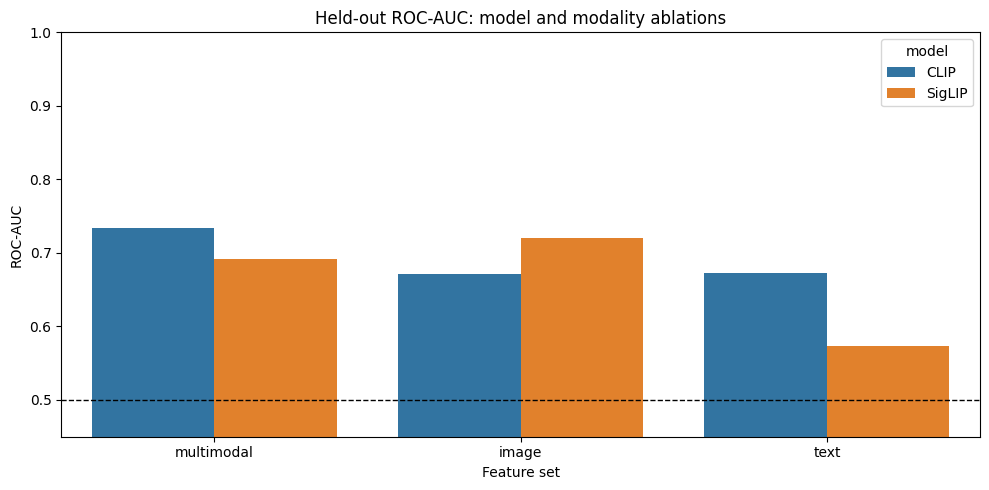

In [30]:
plot_data = results[results["model"] != "Constant baseline"]
plt.figure(figsize=(10, 5))
sns.barplot(data=plot_data, x="features", y="roc_auc", hue="model")
plt.axhline(0.5, color="black", linestyle="--", linewidth=1, label="chance ROC-AUC")
plt.ylim(0.45, 1.0)
plt.title("Held-out ROC-AUC: model and modality ablations")
plt.xlabel("Feature set")
plt.ylabel("ROC-AUC")
plt.tight_layout()
plt.show()


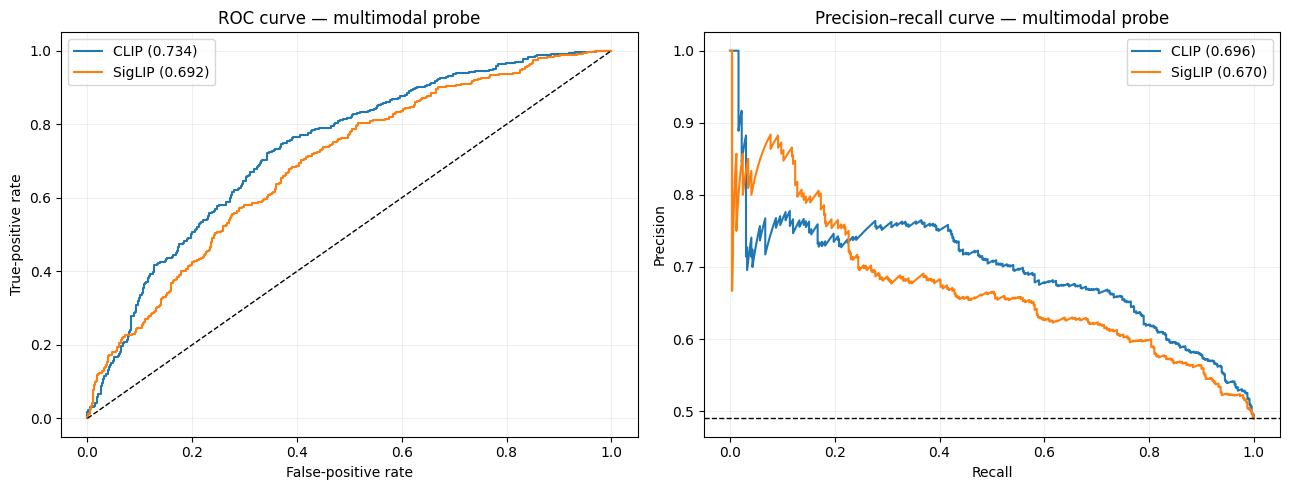

In [31]:
figure, axes = plt.subplots(1, 2, figsize=(13, 5))
for model_name in MODEL_IDS:
    probabilities = test_probabilities[(model_name, "multimodal")]
    false_positive_rate, true_positive_rate, _ = roc_curve(test_labels, probabilities)
    precision, recall, _ = precision_recall_curve(test_labels, probabilities)
    roc_auc = roc_auc_score(test_labels, probabilities)
    average_precision = average_precision_score(test_labels, probabilities)
    axes[0].plot(false_positive_rate, true_positive_rate, label=f"{model_name} ({roc_auc:.3f})")
    axes[1].plot(recall, precision, label=f"{model_name} ({average_precision:.3f})")

axes[0].plot([0, 1], [0, 1], "k--", linewidth=1)
axes[0].set(title="ROC curve — multimodal probe", xlabel="False-positive rate", ylabel="True-positive rate")
axes[1].axhline(test_labels.mean(), color="black", linestyle="--", linewidth=1)
axes[1].set(title="Precision–recall curve — multimodal probe", xlabel="Recall", ylabel="Precision")
for axis in axes:
    axis.legend()
    axis.grid(alpha=0.2)
plt.tight_layout()
plt.show()


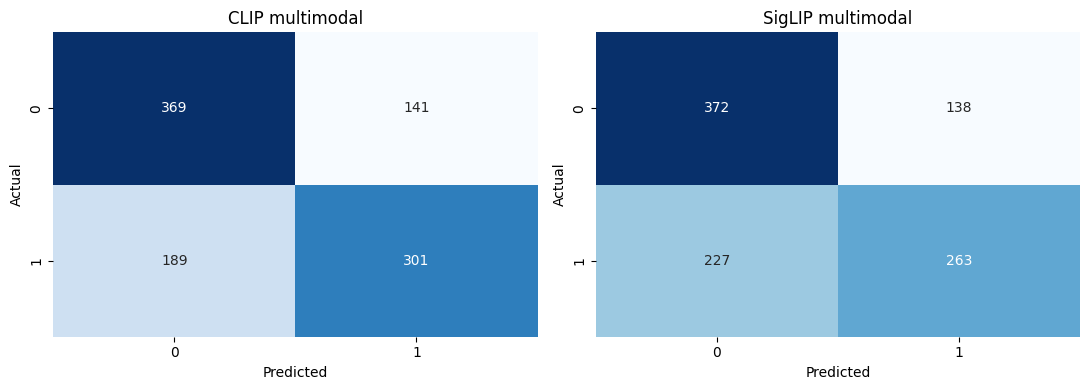

In [32]:
figure, axes = plt.subplots(1, len(MODEL_IDS), figsize=(11, 4))
for axis, model_name in zip(axes, MODEL_IDS):
    probabilities = test_probabilities[(model_name, "multimodal")]
    predictions = (probabilities >= 0.5).astype(int)
    matrix = confusion_matrix(test_labels, predictions)
    sns.heatmap(matrix, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axis)
    axis.set(title=f"{model_name} multimodal", xlabel="Predicted", ylabel="Actual")
plt.tight_layout()
plt.show()


## 6. Qualitative error analysis

Quantitative metrics do not explain *why* a multimodal classifier fails. The next cell ranks confidently wrong predictions. Rendering remains opt-in because the material can be harmful; the compact table lets a reviewer inspect model confidence without automatically displaying images.


In [33]:
def error_frame(model_name, count=12):
    frame = splits["test"].copy()
    frame["probability_hateful"] = test_probabilities[(model_name, "multimodal")]
    frame["prediction"] = (frame["probability_hateful"] >= 0.5).astype(int)
    frame["error_confidence"] = np.where(
        frame["label"] == 1,
        1.0 - frame["probability_hateful"],
        frame["probability_hateful"],
    )
    return (
        frame[frame["label"] != frame["prediction"]]
        .sort_values("error_confidence", ascending=False)
        .head(count)
        .loc[:, ["id", "text", "label", "prediction", "probability_hateful", "img"]]
    )


errors = {model_name: error_frame(model_name) for model_name in MODEL_IDS}
display(errors["CLIP"])
display(errors["SigLIP"])


,id,text,label,prediction,probability_hateful,img
981,49023,african american leaders organizing the la rio...,1,0,0.021214,img/49023.png
789,98137,life has its ups and downs,1,0,0.026731,img/98137.png
134,37092,mentally retarded teenagers with stuffed anima...,0,1,0.965950,img/37092.png
870,73841,which jewish girl is hotter?,0,1,0.964011,img/73841.png
702,28790,monkeys often pick bugs off each other to snac...,1,0,0.038009,img/28790.png
459,27506,ladies and gents i present you with miss islam...,0,1,0.956822,img/27506.png
395,57890,he enemy within ilhan omar linda sarsour ocasi...,1,0,0.044328,img/57890.png
178,57431,black friday deal buy one get one free toaster,0,1,0.953763,img/57431.png
211,45610,a lot of men wearing a white shirt,0,1,0.951604,img/45610.png
942,54196,let's not be hasty. the worldview of the guys ...,0,1,0.951543,img/54196.png


,id,text,label,prediction,probability_hateful,img
743,95072,this guy just friended and unfriended me 45 ti...,1,0,0.010067,img/95072.png
942,54196,let's not be hasty. the worldview of the guys ...,0,1,0.989275,img/54196.png
124,10963,hope on a rope it's what everyone's been waiti...,1,0,0.018691,img/10963.png
118,63502,"in school trip to the zoo, i saw a monkey and ...",0,1,0.977462,img/63502.png
547,80246,car salesman roof of car,1,0,0.025174,img/80246.png
805,78206,authentic lunch in venezuela,1,0,0.026568,img/78206.png
857,31470,they were mentally ill. i had to cure them,1,0,0.029217,img/31470.png
811,10748,can afford to travel from romania to london st...,1,0,0.030890,img/10748.png
584,24836,surrender my guns to a government that doesn't...,0,1,0.960979,img/24836.png
645,8716,for decades bruce fondled her this just in cai...,1,0,0.042875,img/08716.png


In [34]:
def show_error_examples(model_name, count=6):
    examples = errors[model_name].head(count)
    columns = 3
    rows = int(np.ceil(len(examples) / columns))
    figure, axes = plt.subplots(rows, columns, figsize=(14, 4 * rows))
    axes = np.asarray(axes).reshape(-1)
    for axis, (_, row) in zip(axes, examples.iterrows()):
        axis.imshow(Image.open(resolve_image_path(row["img"])).convert("RGB"))
        axis.set_title(
            f"{model_name} | y={row['label']} p={row['probability_hateful']:.2f}\n"
            f"{row['text'][:90]}"
        )
        axis.axis("off")
    for axis in axes[len(examples):]:
        axis.axis("off")
    plt.tight_layout()


if SHOW_EXAMPLES:
    show_error_examples("CLIP")
    show_error_examples("SigLIP")


In [35]:
# Save one prediction file for transparent downstream analysis.
prediction_frame = splits["test"].loc[:, ["id", "label"]].copy()
for (model_name, feature_set), probabilities in test_probabilities.items():
    column = f"{model_name.lower()}_{feature_set}_probability"
    prediction_frame[column] = probabilities
prediction_frame.to_csv(ARTIFACT_DIR / "test_predictions.csv", index=False)

environment = {
    "python": sys.version.split()[0],
    "torch": torch.__version__,
    "transformers": version("transformers"),
    "scikit-learn": version("scikit-learn"),
    "pandas": pd.__version__,
    "device": str(DEVICE),
    "seed": SEED,
    "model_ids": MODEL_IDS,
}
(ARTIFACT_DIR / "run_metadata.json").write_text(
    json.dumps(environment, indent=2), encoding="utf-8"
)
environment


{'python': '3.13.15',
 'torch': '2.11.0+cu130',
 'transformers': '4.57.6',
 'scikit-learn': '1.6.1',
 'pandas': '2.2.3',
 'device': 'cuda',
 'seed': 42,
 'model_ids': {'CLIP': 'openai/clip-vit-base-patch32',
  'SigLIP': 'google/siglip-base-patch16-224'}}

## 7. Interpreting the completed run

After running all cells, report the exact held-out results rather than making a general claim that one encoder is better. A useful summary should answer:

1. Does the multimodal probe beat both unimodal ablations for each encoder?
2. Which encoder has the strongest held-out ROC-AUC and average precision?
3. Are errors concentrated in false positives or false negatives?
4. What patterns appear in confidently wrong examples—OCR difficulty, sarcasm, external cultural knowledge, or image/text contradiction?

On the held-out set, the CLIP multimodal probe achieved ROC-AUC 0.734 and average precision 0.696, compared with 0.692 and 0.670 for SigLIP. CLIP benefited from combining image and text features, while SigLIP’s image-only representation outperformed its simple multimodal concatenation. This suggests that stronger individual embeddings do not guarantee that naive feature fusion will exploit cross-modal information effectively.

The confusion matrices add another useful observation: CLIP found 301 of 490 positive examples, versus 263 for SigLIP, while their false-positive counts were nearly identical—141 versus 138.

### Limitations and responsible use

- This experiment uses frozen encoders and a linear probe; it does not establish the ceiling for either model.
- Dataset performance does not establish readiness for real moderation. Deployment would require subgroup fairness analysis, calibration, human review, appeals, and monitoring for distribution shift.
- The binary label compresses diverse types and targets of hate. It should not be treated as a complete taxonomy of harmful content.
- The dataset license and access terms apply. Images and annotations should not be committed to this repository.
